# Report 1: Fuzzy C-Means on WDBC (Breast Cancer Wisconsin Diagnostic)

## Step 1: Load the raw data and save it as a CSV with named columns

Source: `data/wdbc/wdbc.data` (UCI). The raw file has no header.
Column order follows `wdbc.names`, section 7: field 1 is the ID, field 2 is the diagnosis (M/B),
fields 3-12 are the means, 13-22 the standard errors, and 23-32 the "worst" values of the 10 nucleus features.


In [1]:
from pathlib import Path
import pandas as pd

# Paths are relative to this notebook (Reports/Report 1/src/wdbc/)
REPORT_DIR = Path("../..")
DATA_DIR = REPORT_DIR / "data" / "wdbc"
OUT_DIR = REPORT_DIR / "data" / "wdbc"
OUT_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
# Column names, taken from wdbc.names (section 7)
base = ["radius", "texture", "perimeter", "area", "smoothness",
        "compactness", "concavity", "concave_points", "symmetry",
        "fractal_dimension"]
columns = ["id", "diagnosis"] + [f"{f}_{s}" for s in ("mean", "se", "worst") for f in base]

df = pd.read_csv(DATA_DIR / "wdbc.data", header=None, names=columns)

# Sanity checks (expected values from wdbc.names)
print("shape:", df.shape)                                        # expect (569, 32)
print("missing values:", df.isna().sum().sum())                  # expect 0
print("duplicate ids:", df["id"].duplicated().sum())             # expect 0
print("duplicate feature rows:", df.duplicated(subset=columns[2:]).sum())
print(df["diagnosis"].value_counts())                            # expect B 357, M 212

df.to_csv(OUT_DIR / "wdbc_clean.csv", index=False)
print("saved:", (OUT_DIR / "wdbc_clean.csv").resolve())

shape: (569, 32)
missing values: 0
duplicate ids: 0
duplicate feature rows: 0
diagnosis
B    357
M    212
Name: count, dtype: int64
saved: /home/stefy/Work/University/Master/Anul I/Metode Avansate de Analiza a Datelor/Reports/Report 1/data/wdbc/wdbc_clean.csv


## Step 2: Exploratory look at the features

Goal: measure the properties of the 30 features before choosing feature set, scaling and transformations.
Nothing is decided here; the outputs are evidence for the choices in Step 3.

- 2a: summary statistics (ranges and scales of the features)
- 2b: skewness of each feature
- 2c: Pearson (linear) and Spearman (rank, monotonic) correlation matrices between features
- 2d: distribution of each feature (boxplots on standardized values, for comparability only)
- 2e: PCA explained variance (how much independent information the 30 features carry)

In [3]:
import numpy as np
import matplotlib.pyplot as plt

FIG_DIR = REPORT_DIR / "figures" / "wdbc"
FIG_DIR.mkdir(parents=True, exist_ok=True)

feature_cols = columns[2:]
X = df[feature_cols]

### 2a: Summary statistics

In [4]:
summary = X.describe().T
summary.to_csv(OUT_DIR / "wdbc_summary.csv")

print("smallest std:", summary["std"].idxmin(), f"{summary['std'].min():.6g}")
print("largest std: ", summary["std"].idxmax(), f"{summary['std'].max():.6g}")
print("ratio largest/smallest std:", f"{summary['std'].max() / summary['std'].min():.3g}")
summary

smallest std: fractal_dimension_se 0.00264607
largest std:  area_worst 569.357
ratio largest/smallest std: 2.15e+05


,count,mean,std,min,25%,50%,75%,max
radius_mean,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
texture_mean,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
perimeter_mean,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
area_mean,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
smoothness_mean,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
compactness_mean,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
concavity_mean,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
concave_points_mean,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
symmetry_mean,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
fractal_dimension_mean,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


### 2b: Skewness

In [5]:
skew = X.skew().sort_values(ascending=False).rename("skewness")
skew.to_csv(OUT_DIR / "wdbc_skewness.csv")

# Common rule of thumb: |skew| < 0.5 roughly symmetric, 0.5-1 moderate, > 1 strong
print("features with |skew| > 1:", (skew.abs() > 1).sum(), "of", len(skew))
skew

features with |skew| > 1: 22 of 30


area_se                    5.447186
concavity_se               5.110463
fractal_dimension_se       3.923969
perimeter_se               3.443615
radius_se                  3.088612
smoothness_se              2.314450
symmetry_se                2.195133
compactness_se             1.902221
area_worst                 1.859373
fractal_dimension_worst    1.662579
texture_se                 1.646444
area_mean                  1.645732
compactness_worst          1.473555
concave_points_se          1.444678
symmetry_worst             1.433928
concavity_mean             1.401180
fractal_dimension_mean     1.304489
compactness_mean           1.190123
concave_points_mean        1.171180
concavity_worst            1.150237
perimeter_worst            1.128164
radius_worst               1.103115
perimeter_mean             0.990650
radius_mean                0.942380
symmetry_mean              0.725609
texture_mean               0.650450
texture_worst              0.498321
concave_points_worst       0

### 2c: Correlation matrices (Pearson and Spearman)

Pearson measures linear association on the raw values; Spearman is Pearson computed on ranks, so it measures
monotonic association and is less affected by skewness and outliers. Comparing the two shows where they differ.

In [ ]:
THRESHOLD = 0.9
corrs = {m: X.corr(method=m) for m in ("pearson", "spearman")}
symbol = {"pearson": "r", "spearman": "rho"}

for method, corr in corrs.items():
    corr.to_csv(OUT_DIR / f"wdbc_correlation_{method}.csv")

    fig, ax = plt.subplots(figsize=(11, 9))
    im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(feature_cols)), feature_cols, rotation=90, fontsize=7)
    ax.set_yticks(range(len(feature_cols)), feature_cols, fontsize=7)
    fig.colorbar(im, ax=ax, label=f"{method.capitalize()} {symbol[method]}")
    ax.set_title(f"WDBC: {method.capitalize()} correlation between the 30 features")
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"wdbc_correlation_{method}.png", dpi=200)
    plt.show()

# Side-by-side table of all feature pairs (upper triangle), to check the heatmaps numerically
mask = np.triu(np.ones(corrs["pearson"].shape, dtype=bool), k=1)
pairs = pd.DataFrame({m: c.where(mask).stack().dropna() for m, c in corrs.items()})  # 30*29/2 = 435 pairs
pairs["difference"] = pairs["spearman"] - pairs["pearson"]
pairs.to_csv(OUT_DIR / "wdbc_correlation_pairs.csv")

for method in corrs:
    print(f"{method}: pairs with |{symbol[method]}| > {THRESHOLD}:", (pairs[method].abs() > THRESHOLD).sum(), "of", len(pairs))

print("\npairs above the threshold under either method:")
pairs[(pairs["pearson"].abs() > THRESHOLD) | (pairs["spearman"].abs() > THRESHOLD)].sort_values("pearson", ascending=False)

### 2d: Feature distributions

Values are z-scored here **only to put all features on one axis**; this is not the preprocessing decision.

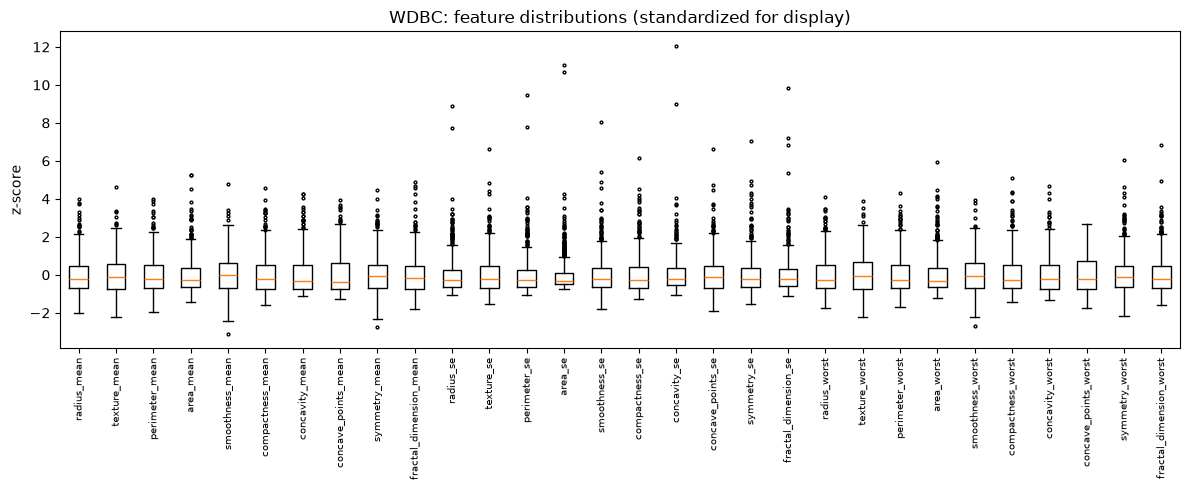

rows with at least one feature outside the whiskers: 171 of 569


area_se                    65
radius_se                  38
perimeter_se               38
area_worst                 35
smoothness_se              30
fractal_dimension_se       28
compactness_se             28
symmetry_se                27
area_mean                  25
fractal_dimension_worst    24
symmetry_worst             23
concavity_se               22
texture_se                 20
concave_points_se          19
concavity_mean             18
radius_worst               17
compactness_worst          16
compactness_mean           16
symmetry_mean              15
fractal_dimension_mean     15
perimeter_worst            15
radius_mean                14
perimeter_mean             13
concavity_worst            12
concave_points_mean        10
texture_mean                7
smoothness_worst            7
smoothness_mean             6
texture_worst               5
concave_points_worst        0
Name: n_outliers_1.5IQR, dtype: int64

In [7]:
Z = (X - X.mean()) / X.std()

fig, ax = plt.subplots(figsize=(12, 5))
ax.boxplot(Z.values, tick_labels=feature_cols, whis=1.5, flierprops={"markersize": 2})
ax.set_xticklabels(feature_cols, rotation=90, fontsize=7)
ax.set_ylabel("z-score")
ax.set_title("WDBC: feature distributions (standardized for display)")
fig.tight_layout()
fig.savefig(FIG_DIR / "wdbc_boxplots.png", dpi=200)
plt.show()

# Count of points outside the 1.5*IQR whiskers, per feature
q1, q3 = X.quantile(0.25), X.quantile(0.75)
iqr = q3 - q1
outliers = ((X < q1 - 1.5 * iqr) | (X > q3 + 1.5 * iqr)).sum().sort_values(ascending=False).rename("n_outliers_1.5IQR")
outliers.to_csv(OUT_DIR / "wdbc_outlier_counts.csv")
print("rows with at least one feature outside the whiskers:",
      ((X < q1 - 1.5 * iqr) | (X > q3 + 1.5 * iqr)).any(axis=1).sum(), "of", len(X))
outliers

### 2e: PCA explained variance

PCA on the **correlation matrix** (equivalent to PCA on z-scored features), so that features with large units
(e.g. area) do not dominate. Eigenvalues are the variances of the principal components; their share of the total
(= 30, the number of features) is the explained variance. Computed directly with NumPy so every step is visible.
Exploration only: clustering is not run on these components.

components needed for 80% of the variance: 5
components needed for 90% of the variance: 7
components needed for 95% of the variance: 10
components needed for 99% of the variance: 17
components with eigenvalue > 1 (Kaiser criterion): 6


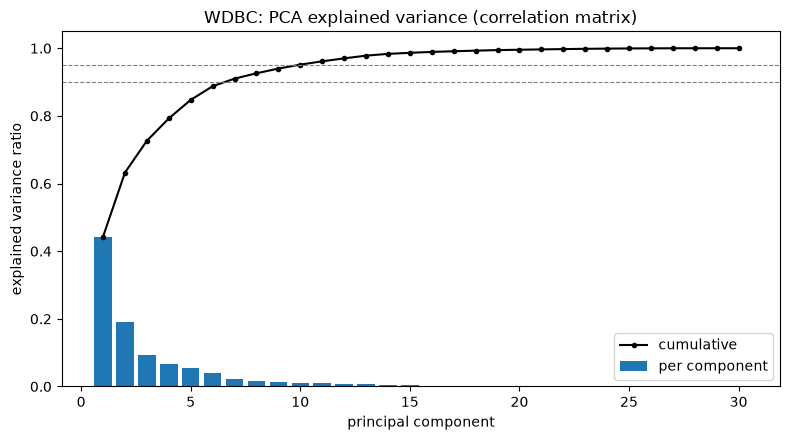

,component,eigenvalue,explained_variance_ratio,cumulative
0,1,13.281608,0.442720,0.442720
1,2,5.691355,0.189712,0.632432
2,3,2.817949,0.093932,0.726364
3,4,1.980640,0.066021,0.792385
4,5,1.648731,0.054958,0.847343
5,6,1.207357,0.040245,0.887588
6,7,0.675220,0.022507,0.910095
7,8,0.476617,0.015887,0.925983
8,9,0.416895,0.013896,0.939879
9,10,0.350693,0.011690,0.951569


In [8]:
R = X.corr(method="pearson").to_numpy()
eigvals = np.linalg.eigvalsh(R)[::-1]          # symmetric matrix -> real eigenvalues, sorted descending

pca = pd.DataFrame({
    "component": np.arange(1, len(eigvals) + 1),
    "eigenvalue": eigvals,
    "explained_variance_ratio": eigvals / eigvals.sum(),
})
pca["cumulative"] = pca["explained_variance_ratio"].cumsum()
pca.to_csv(OUT_DIR / "wdbc_pca_explained_variance.csv", index=False)

for level in (0.80, 0.90, 0.95, 0.99):
    k = int((pca["cumulative"] >= level).idxmax()) + 1
    print(f"components needed for {level:.0%} of the variance: {k}")
print("components with eigenvalue > 1 (Kaiser criterion):", (pca["eigenvalue"] > 1).sum())

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(pca["component"], pca["explained_variance_ratio"], label="per component")
ax.plot(pca["component"], pca["cumulative"], marker="o", markersize=3, color="black", label="cumulative")
for level in (0.90, 0.95):
    ax.axhline(level, linestyle="--", linewidth=0.8, color="grey")
ax.set_xlabel("principal component")
ax.set_ylabel("explained variance ratio")
ax.set_title("WDBC: PCA explained variance (correlation matrix)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "wdbc_pca_explained_variance.png", dpi=200)
plt.show()

pca.head(10)